<a href="https://colab.research.google.com/github/alansanthosh042005-cyber/Windmill/blob/main/CAD_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

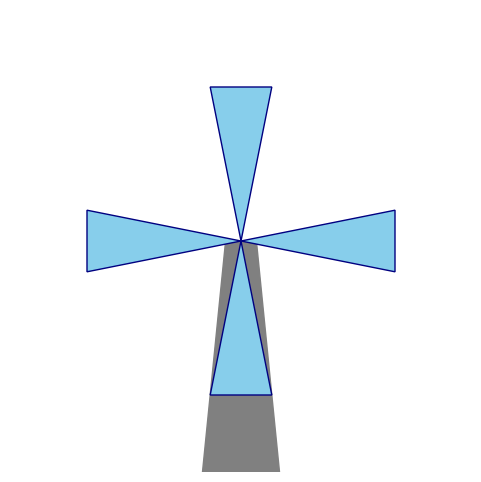

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. SETUP THE SCENE ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_aspect('equal')
ax.set_xlim(-6, 6)
ax.set_ylim(0, 12)
ax.axis('off') # Hide axes for a cleaner sky

# Draw the stationary windmill tower
ax.fill([-1, 1, 0.4, -0.4], [0, 0, 6, 6], color='gray')

# The "Fixed Point" where the blades attach
cx, cy = 0, 6

# Define a single blade shape (a triangle) centered at origin (0,0)
# Matrix shape is 2x3: [[x1, x2, x3], [y1, y2, y3]]
blade_coords = np.array([
    [0, 0.8, -0.8],  # X coordinates
    [0, 4.0,  4.0]   # Y coordinates
])

# Create 4 empty polygon objects to represent our blades
blades = [ax.fill([], [], color='skyblue', edgecolor='navy')[0] for _ in range(4)]


# --- 2. MATRIX REPRESENTATION ---
def apply_rotation_matrix(points, angle_degrees):
    """Rotates a set of 2D points around the origin using a rotation matrix."""
    theta = np.radians(angle_degrees)

    # Standard 2D Rotation Matrix
    R = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    # Matrix multiplication: R * points
    return R @ points


# --- 3. COMPOSITE TRANSFORMATIONS & ANIMATION ---
def update_frame(frame):
    # Base rotation that increases over time
    current_angle = frame * -5

    for i in range(4):
        # Space the 4 blades 90 degrees apart
        blade_angle = current_angle + (i * 90)

        # Transformation 1: Rotate the blade around the origin (0,0)
        rotated_points = apply_rotation_matrix(blade_coords, blade_angle)

        # Transformation 2: Translate to the fixed point (cx, cy)
        translated_x = rotated_points[0, :] + cx
        translated_y = rotated_points[1, :] + cy

        # Update the visual polygons with the new calculated coordinates
        # column_stack pairs the X and Y coordinates back together for matplotlib
        blades[i].set_xy(np.column_stack([translated_x, translated_y]))

    return blades

# Run the animation loop (72 frames, 50ms per frame)
ani = animation.FuncAnimation(fig, update_frame, frames=72, interval=50, blit=True)

plt.show()